In [4]:
import sys
from pathlib import Path
import random
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'src/load_dataset/iam.py').exists())
sys.path.insert(0, str(ROOT))
import torch
from huggingface_hub import HfApi
from src.load_dataset.iam import load_iam_dataset
from src.load_dataset.bentham import load_bentham_dataset
SEED = 42
SAMPLE_COUNT = 100
iam_revision = HfApi().dataset_info('Teklia/IAM-line').sha
full_iam = load_iam_dataset('validation', revision=iam_revision)
full_bentham = load_bentham_dataset('validation')
indices = {name: sorted(random.Random(SEED).sample(range(len(ds)), SAMPLE_COUNT))
           for name, ds in [('iam', full_iam), ('bentham', full_bentham)]}
iam = full_iam.select(indices['iam']).add_column('id', [f'sample_{i}' for i in indices['iam']])
bentham = full_bentham.select(indices['bentham'])
print('Validation samples:', len(iam), len(bentham), '| full sizes:', len(full_iam), len(full_bentham))
print('MPS available:', torch.backends.mps.is_available())

Ignoring part of dataset_info from the dataset card: The `splits` field in YAML is malformed or missing the name/num_examples/num_bytes fields


Flattening the indices:   0%|          | 0/100 [00:00<?, ? examples/s]

Validation samples: 100 100 | full sizes: 976 1415
MPS available: True


# Non-local means parameter validation

Five configurations plus an untreated baseline on 100 seeded validation lines per dataset (seed 42). Fixed ordered source indices are recorded. Source validation splits: IAM 976, Bentham 1,415. No test data or training. Select the lowest equal-dataset mean corpus CER, with WER breaking ties; also report per-dataset winners. Baseline is eligible to win. This is a subset parameter search, not a final performance estimate.

Configurations: h=1, 3, 7 with template=7/search=21; template=3 at h=3; search=11 at h=3. h_color stays at 3. IAM is grayscale, so h_color is inactive. Bentham RGBA is composited onto white for both baseline and denoising. Originals stay unchanged. Whitespace is collapsed; case/punctuation retained. IAM is within TrOCR's training domain, while Bentham is historical handwriting.

Results and batch checkpoints are under results/validation/denoising/<UTC study ID>/. Rerun only the evaluation cell to resume within this kernel. The earlier interrupted full-split study is retained separately. Freeze any selected settings before test evaluation.

In [5]:
from datetime import datetime, timezone
from importlib.metadata import version
import json
import random
import numpy as np
from src.models.trocr import TrOCRRecognizer
from src.validation.denoising import configurations, evaluate, summarize

SEED = 42
BATCH_SIZE = 8
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
OUTPUT = ROOT / 'results/validation/denoising' / datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
OUTPUT.mkdir(parents=True)
model = TrOCRRecognizer(device='mps' if torch.backends.mps.is_available() else 'cpu')
configs = configurations()
from src.load_dataset.bentham import REVISION, ARCHIVES
metadata = {'seed': SEED, 'split': 'validation', 'batch_size': BATCH_SIZE,
    'model': model.to_config(), 'iam_revision': iam_revision,
    'bentham_revision': REVISION, 'bentham_archive_sha256': ARCHIVES,
    'datasets': {name: {'count': len(ds), 'fingerprint': ds._fingerprint, 'columns': ds.column_names} for name, ds in [('iam', iam), ('bentham', bentham)]},
    'configurations': {name: step.to_config() if step else None for name, step in configs.items()},
    'selection': 'lowest equal-dataset mean corpus CER; WER tie-breaker; baseline eligible',
    'normalization': 'collapse whitespace, retain case and punctuation',
    'versions': {p: version(p) for p in ['torch', 'transformers', 'datasets', 'huggingface-hub', 'Pillow', 'numpy', 'pandas', 'jiwer', 'opencv-python-headless']}}
(OUTPUT / 'metadata.json').write_text(json.dumps(metadata, indent=2))
print('Output:', OUTPUT)
print('Configurations:', list(configs))

Loading weights:   0%|          | 0/478 [00:00<?, ?it/s]

[transformers] VisionEncoderDecoderModel LOAD REPORT from: microsoft/trocr-base-handwritten
Key                         | Status  | 
----------------------------+---------+-
encoder.pooler.dense.weight | MISSING | 
encoder.pooler.dense.bias   | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Output: /Users/vmendoza/Documents/Lakehead/RM/COMP-5112-Research-Methodology/results/validation/denoising/20261112T000633091905Z
Configurations: ['baseline', 'nlm_h1', 'nlm_h3', 'nlm_h5', 'nlm_h7', 'nlm_h10', 'nlm_template3', 'nlm_template5', 'nlm_search11', 'nlm_search31', 'nlm_color7']


In [8]:
from importlib import reload
import src.validation.denoising as denoising_validation
reload(denoising_validation)
configs = denoising_validation.configurations()
evaluate = denoising_validation.evaluate
summarize = denoising_validation.summarize
metadata.update({'sample_count_per_dataset': SAMPLE_COUNT, 'sample_indices': indices,
    'full_split_sizes': {'iam': len(full_iam), 'bentham': len(full_bentham)},
    'scope': 'seeded validation subset parameter search, not final test evaluation',
    'configurations': {name: step.to_config() if step else None for name, step in configs.items()},
    'denoising_run_count': 5})
(OUTPUT / 'metadata.json').write_text(json.dumps(metadata, indent=2))
print('Five denoising runs plus baseline:', list(configs))

Five denoising runs plus baseline: ['baseline', 'nlm_h1', 'nlm_h3', 'nlm_h7', 'nlm_template3', 'nlm_search11']


In [9]:
summaries = []
for name, transform in configs.items():
    for dataset_name, dataset in [('iam', iam), ('bentham', bentham)]:
        result = evaluate(dataset, dataset_name, model, name, transform, OUTPUT, BATCH_SIZE)
        summaries.append(result)
        print(result, flush=True)
        if len(summaries) >= 2:
            table, ranking, winners = summarize(summaries, OUTPUT)
table, ranking, winners = summarize(summaries, OUTPUT)
display(table, ranking, winners)

{'dataset': 'iam', 'configuration': 'baseline', 'sample_count': 100, 'cer': 0.011541072640868975, 'wer': 0.0438034188034188, 'preprocessing_seconds': 0.0013829600011376897, 'inference_seconds': 30.22164220799823}
{'dataset': 'bentham', 'configuration': 'baseline', 'sample_count': 100, 'cer': 0.15963923337091318, 'wer': 0.2954796030871003, 'preprocessing_seconds': 0.034089245003087854, 'inference_seconds': 28.429703711000002}
{'dataset': 'iam', 'configuration': 'nlm_h1', 'sample_count': 100, 'cer': 0.011541072640868975, 'wer': 0.0438034188034188, 'preprocessing_seconds': 6.530945245005569, 'inference_seconds': 29.514186833998792}
bentham/nlm_h1: 80/100
bentham/nlm_h1: 100/100
{'dataset': 'bentham', 'configuration': 'nlm_h1', 'sample_count': 100, 'cer': 0.15467869222096955, 'wer': 0.2932745314222712, 'preprocessing_seconds': 12.822938622000947, 'inference_seconds': 28.879773541999384}
iam/nlm_h3: 8/100
iam/nlm_h3: 80/100
iam/nlm_h3: 100/100
{'dataset': 'iam', 'configuration': 'nlm_h3', '

,dataset,configuration,sample_count,cer,wer,preprocessing_seconds,inference_seconds,cer_delta_vs_baseline,wer_delta_vs_baseline
0,iam,baseline,100,0.011541,0.043803,0.001383,30.221642,0.000000,0.000000
1,bentham,baseline,100,0.159639,0.295480,0.034089,28.429704,0.000000,0.000000
2,iam,nlm_h1,100,0.011541,0.043803,6.530945,29.514187,0.000000,0.000000
3,bentham,nlm_h1,100,0.154679,0.293275,12.822939,28.879774,-0.004961,-0.002205
4,iam,nlm_h3,100,0.011767,0.043803,5.588846,29.247813,0.000226,0.000000
5,bentham,nlm_h3,100,0.165051,0.302095,13.374917,28.458132,0.005411,0.006615
6,iam,nlm_h7,100,0.010862,0.040598,6.371633,29.241174,-0.000679,-0.003205
7,bentham,nlm_h7,100,0.194814,0.341786,14.288525,30.192075,0.035175,0.046307
8,iam,nlm_template3,100,0.011994,0.044872,6.163595,29.354086,0.000453,0.001068
9,bentham,nlm_template3,100,0.158737,0.295480,13.295351,28.865907,-0.000902,0.000000


,cer,wer
configuration,,
nlm_h1,0.083110,0.168539
nlm_template3,0.085365,0.170176
baseline,0.085590,0.169642
nlm_search11,0.086154,0.173500
nlm_h3,0.088409,0.172949
nlm_h7,0.102838,0.191192


,dataset,configuration,sample_count,cer,wer,preprocessing_seconds,inference_seconds,cer_delta_vs_baseline,wer_delta_vs_baseline
0,bentham,nlm_h1,100,0.154679,0.293275,12.822939,28.879774,-0.004961,-0.002205
1,iam,nlm_h7,100,0.010862,0.040598,6.371633,29.241174,-0.000679,-0.003205


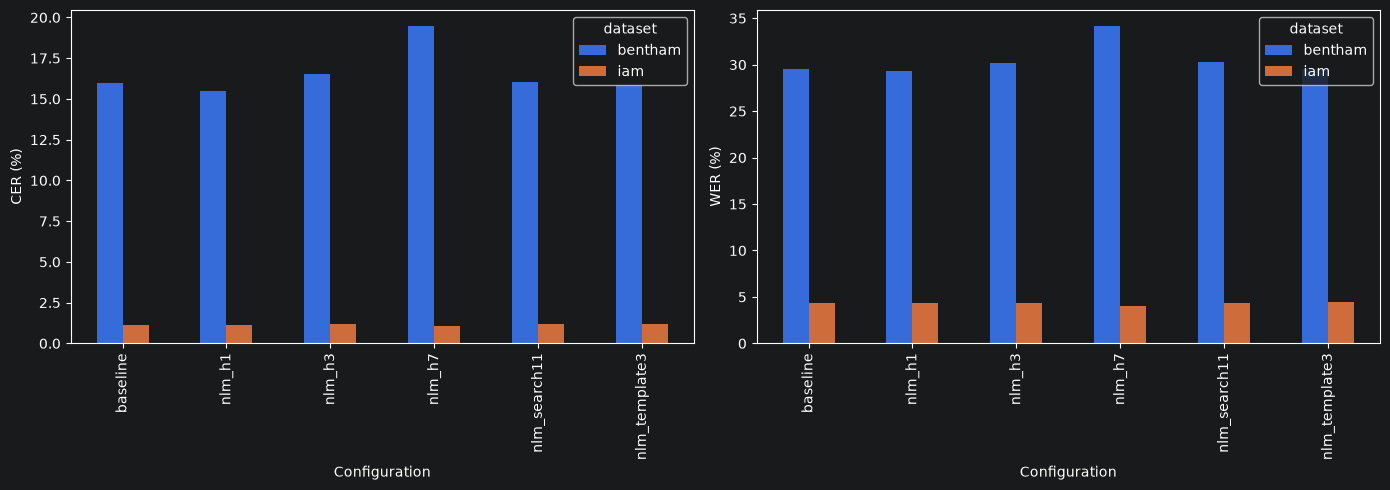

{
  "best_overall": "nlm_h1",
  "best_denoising": "nlm_h1",
  "denoising_parameters": {
    "name": "non_local_means",
    "enabled": true,
    "h": 1.0,
    "h_color": 3.0,
    "template_window_size": 7,
    "search_window_size": 21
  },
  "criterion": "lowest equal-dataset mean corpus CER; WER tie-breaker; baseline eligible",
  "dataset_winners": [
    {
      "dataset": "bentham",
      "configuration": "nlm_h1",
      "cer": 0.15467869222096955,
      "wer": 0.2932745314222712
    },
    {
      "dataset": "iam",
      "configuration": "nlm_h7",
      "cer": 0.010862186014935505,
      "wer": 0.0405982905982906
    }
  ]
}
Subset validation optimum; confirm on validation data before freezing final test parameters.


In [10]:
import matplotlib.pyplot as plt
assert len(table) == 12, 'Study incomplete: need 5 denoising configurations plus baseline on both datasets'
assert table.groupby('dataset').sample_count.nunique().eq(1).all()
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, metric in zip(axes, ['cer', 'wer']):
    table.pivot(index='configuration', columns='dataset', values=metric).mul(100).plot.bar(ax=ax)
    ax.set_ylabel(metric.upper() + ' (%)')
    ax.set_xlabel('Configuration')
fig.tight_layout()
fig.savefig(OUTPUT / 'corpus_error_rates.png', dpi=160, bbox_inches='tight')
plt.show()
best_nlm = ranking.drop(index='baseline').index[0]
best = ranking.index[0]
selection = {'best_overall': best, 'best_denoising': best_nlm,
             'denoising_parameters': configs[best_nlm].to_config(),
             'criterion': metadata['selection'],
             'dataset_winners': winners[['dataset', 'configuration', 'cer', 'wer']].to_dict('records')}
(OUTPUT / 'selection.json').write_text(json.dumps(selection, indent=2))
print(json.dumps(selection, indent=2))
print('Subset validation optimum; confirm on validation data before freezing final test parameters.')